# The Problem

*The rising influence of user-generated online reviews has led to growing incentive for businesses to solicit and manufacture DECEPTIVE OPINION SPAM — fictitious reviews that have been deliberately written to sound authentic and deceive the reader.*

*In Todays digital era, Your purchase decisions are increasingly influenced by user-generated online reviews of products and services. Accordingly, there is a growing incentive for businesses to solicit and manufacture fictitious reviews that have been deliberately written to sound authentic and deceive the reader.*

*Reviews intended to promote or hype an offering, and which therefore express a positive sentiment towards the offering, are called `positive deceptive opinion spam`. In contrast, reviews intended to disparage or slander
competitive offerings, and which therefore express a negative sentiment towards the offering, are called `negative deceptive opinion spam`.*

***In this Data we distinguish between two kinds of deceptive opinion spam, depending on the sentiment expressed in the review i.e positive Deceptive and Negative Deceptive Review. We will build a end to end solution which will help to pass a review and will give you back a label deciding whether the review is Deceptive or Not.***

### Importing Dependencies

In [4]:
import pandas as pd
pd.set_option('display.max_columns',100) # Displaying max columns present in the dataframe
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook
from collections import Counter

import wget 
import zipfile
import os
import glob
import ntpath
import spacy
import string
import sys
from wordcloud import WordCloud, STOPWORDS 
import matplotlib.pyplot as plt 
import pandas as pd

### Collecting Data
    What ways do you think exist to collect data?
---
    There are a lot of ways to collect data, sometimes we directly download some structured files sometimes databases and sometimes even from pictures. Yet another way to collect data is from weblinks that contain any of the above mentioned formats

*Data set we are going use is open source and can be retrieved from this [link](https://myleott.com/op-spam.html).*

In [2]:
wget.download('https://myleott.com/op_spam_v1.4.zip')

100% [..........................................................................] 1172634 / 1172634

'op_spam_v1.4 (1).zip'

*This downloads a op_spam_v1.4.zip file, lets go a head a unzip it.*

In [5]:
with zipfile.ZipFile('op_spam_v1.4.zip', 'r') as z:
    z.extractall()

### Importing Data

*The following function gives a tree structure of the files inside `op_spam_v1.4/` folder*

In [6]:
def list_files(startpath):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent =  ' ' * 6 * (level)
        print('{}{}/'.format(indent, os.path.basename(root)))
        subindent = ' ' * 6 * (level + 1)
        for f in files[:5]:
            print('{}{}'.format(subindent, f))

In [7]:
list_files('op_spam_v1.4/')

/
      LICENSE
      README.md
negative_polarity/
      deceptive_from_MTurk/
            fold1/
                  d_hilton_1.txt
                  d_hilton_10.txt
                  d_hilton_11.txt
                  d_hilton_12.txt
                  d_hilton_13.txt
            fold2/
                  d_affinia_1.txt
                  d_affinia_10.txt
                  d_affinia_11.txt
                  d_affinia_12.txt
                  d_affinia_13.txt
            fold3/
                  d_conrad_1.txt
                  d_conrad_10.txt
                  d_conrad_11.txt
                  d_conrad_12.txt
                  d_conrad_13.txt
            fold4/
                  d_homewood_1.txt
                  d_homewood_10.txt
                  d_homewood_11.txt
                  d_homewood_12.txt
                  d_homewood_13.txt
            fold5/
                  d_allegro_1.txt
                  d_allegro_10.txt
                  d_allegro_11.txt
                  d_allegro_12.

*`op_spam_v1.4/` folder has two sub-folders `negative_polarity/` and `positive_polarity/`*

*Now Each polarity folder has two sub-folder `deceptive_from_MTurk/` and `truthful_from_TripAdvisor/`*

*Each of the above folders consist of 20 reviews for each of the 20 most popular Chicago hotels. The files are named according to the following conventions:*

- Directories prefixed with fold correspond to a single fold from the cross-validation experiments.
- Files are named according to the format %c_%h_%i.txt, where:
    - %c denotes the class: (t)ruthful or (d)eceptive
    - %h denotes the hotel:
        - affinia: Affinia Chicago (now MileNorth, A Chicago Hotel)
        - allegro: Hotel Allegro Chicago - a Kimpton Hotel
        - amalfi: Amalfi Hotel Chicago
        - ambassador: Ambassador East Hotel (now PUBLIC Chicago)
        - conrad: Conrad Chicago
        - fairmont: Fairmont Chicago Millennium Park
        - hardrock: Hard Rock Hotel Chicago
        - hilton: Hilton Chicago
        - homewood: Homewood Suites by Hilton Chicago Downtown
        - hyatt: Hyatt Regency Chicago
        - intercontinental: InterContinental Chicago
        - james: James Chicago
        - knickerbocker: Millennium Knickerbocker Hotel Chicago
        - monaco: Hotel Monaco Chicago - a Kimpton Hotel
        - omni: Omni Chicago Hotel
        - palmer: The Palmer House Hilton
        - sheraton: Sheraton Chicago Hotel and Towers
        - sofitel: Sofitel Chicago Water Tower
        - swissotel: Swissotel Chicago
        - talbott: The Talbott Hotel
- %i serves as a counter to make the filename unique

### Reading the files in a Dataframe

*Reading Positive reviews files inside positive_polarity/.*

In [9]:
# Accessing data for Positive True Reviews
path = 'op_spam_v1.4/positive_polarity/'
files = [f for f in glob.glob(path + "**/*.txt", recursive=True)]

glob searches for files with the regex <code>\*\*/\*.txt</code> inside folders and sub-folders.

In [10]:
files[:5]

['op_spam_v1.4/positive_polarity\\deceptive_from_MTurk\\fold1\\d_hilton_1.txt',
 'op_spam_v1.4/positive_polarity\\deceptive_from_MTurk\\fold1\\d_hilton_10.txt',
 'op_spam_v1.4/positive_polarity\\deceptive_from_MTurk\\fold1\\d_hilton_11.txt',
 'op_spam_v1.4/positive_polarity\\deceptive_from_MTurk\\fold1\\d_hilton_12.txt',
 'op_spam_v1.4/positive_polarity\\deceptive_from_MTurk\\fold1\\d_hilton_13.txt']

In [11]:
len(files)

800

*There are total 800 reviews in positive sentiment folder, out of which 400 are true and 400 are deceptive.*

*Now we iterate over each filename in list and read them into a DataFrame.*

In [12]:
filename= list()
reviews= list()
for file in files:
    with open(file, 'r') as f:
        filename.append(ntpath.basename(file))
        reviews.append(f.read())
positive_df= pd.DataFrame({'filename': filename, 'review': reviews})
positive_df.head()

,filename,review
0,d_hilton_1.txt,My husband and I satayed for two nights at the...
1,d_hilton_10.txt,The Hilton Chicago was amazing!! It is close t...
2,d_hilton_11.txt,Excellent hotel in the heart of Chicago. The r...
3,d_hilton_12.txt,I stayed at the Hilton Chicago for my cousins ...
4,d_hilton_13.txt,The Downtown Chicago Hilton was the best combi...


In [13]:
positive_df.shape

(800, 2)

Use of `ntpath.basename`

`ntpath.basename('a/b/c/abc.txt')`<br>
> `abc.txt`

*It returns the filename from the whole path.*

*As we are done reading all the positive files in DataFrame, Now lets start Reading Negative reviews files inside negative_polarity/. the same way just we need to change the pathname*

In [14]:
path = 'op_spam_v1.4/negative_polarity/'
files = [f for f in glob.glob(path + "**/*.txt", recursive=True)]
filename= list()
reviews= list()
for file in files:
    with open(file, 'r') as f:
        filename.append(ntpath.basename(file))
        reviews.append(f.read())
neagtive_df= pd.DataFrame({'filename': filename, 'review': reviews})
neagtive_df.head()

,filename,review
0,d_hilton_1.txt,We stayed at the Schicago Hilton for 4 days an...
1,d_hilton_10.txt,Hotel is located 1/2 mile from the train stati...
2,d_hilton_11.txt,I made my reservation at the Hilton Chicago be...
3,d_hilton_12.txt,"When most people think Hilton, they think luxu..."
4,d_hilton_13.txt,My husband and I recently stayed stayed at the...


In [15]:
neagtive_df.head()

,filename,review
0,d_hilton_1.txt,We stayed at the Schicago Hilton for 4 days an...
1,d_hilton_10.txt,Hotel is located 1/2 mile from the train stati...
2,d_hilton_11.txt,I made my reservation at the Hilton Chicago be...
3,d_hilton_12.txt,"When most people think Hilton, they think luxu..."
4,d_hilton_13.txt,My husband and I recently stayed stayed at the...


### Data Preparation

    How are we supposed to prepare the data? what steps do you think will help us?
---
    
    Our very First step in Data Preparation is to merge positive and negative DataFrames and assigning a label to it specifying whether the review is positive or negative.
    Then we can extract the hotel name for better exploratory data analysis
    Then the actual polarity of the review (d - deceptive, t - true) this d or t will be the first character of filename

In [16]:
positive_df['polarity']= ['positive'] * positive_df.shape[0]
neagtive_df['polarity']= ['negative'] * neagtive_df.shape[0]

In [17]:
# Concatenating DataFrames
final_df= pd.concat([positive_df, neagtive_df], axis=0, ignore_index= True)

In [18]:
final_df.head()

,filename,review,polarity
0,d_hilton_1.txt,My husband and I satayed for two nights at the...,positive
1,d_hilton_10.txt,The Hilton Chicago was amazing!! It is close t...,positive
2,d_hilton_11.txt,Excellent hotel in the heart of Chicago. The r...,positive
3,d_hilton_12.txt,I stayed at the Hilton Chicago for my cousins ...,positive
4,d_hilton_13.txt,The Downtown Chicago Hilton was the best combi...,positive


In [19]:
final_df.tail()

,filename,review,polarity
1595,t_palmer_5.txt,The Palmer House has a beautiful lobby with a ...,negative
1596,t_palmer_6.txt,great expectations from the hotel of THE FUGIT...,negative
1597,t_palmer_7.txt,"For a Hilton hotel I was very unimpressed, the...",negative
1598,t_palmer_8.txt,Beautiful historic hotel -- and since I'm in h...,negative
1599,t_palmer_9.txt,The heating in our room didn't work and wasn't...,negative


In [21]:
final_df['hotel']= final_df.filename.str.extract('_(.*)_')
final_df.hotel.head()

0    hilton
1    hilton
2    hilton
3    hilton
4    hilton
Name: hotel, dtype: object

In [22]:
final_df['label']= final_df.filename.str[0].map({'d':'deceptive', 't': 'true'})

In [23]:
final_df['label'].head()

0    deceptive
1    deceptive
2    deceptive
3    deceptive
4    deceptive
Name: label, dtype: object

In [24]:
final_df.head()

,filename,review,polarity,hotel,label
0,d_hilton_1.txt,My husband and I satayed for two nights at the...,positive,hilton,deceptive
1,d_hilton_10.txt,The Hilton Chicago was amazing!! It is close t...,positive,hilton,deceptive
2,d_hilton_11.txt,Excellent hotel in the heart of Chicago. The r...,positive,hilton,deceptive
3,d_hilton_12.txt,I stayed at the Hilton Chicago for my cousins ...,positive,hilton,deceptive
4,d_hilton_13.txt,The Downtown Chicago Hilton was the best combi...,positive,hilton,deceptive


*We don't need filename now lets remove it.*

In [25]:
final_df.drop('filename', axis=1, inplace= True)

In [26]:
# Save this to a CSV
final_df.to_csv('final_df.csv', index= False)

In [28]:
df= final_df.copy(deep = True)

    We believe by now you understand why we use "deep" parameter in copy. For those of you who aren't aware, deep = True creates a new object all together at a new memory location while a shallow copy only points the new variable to existing memory location

### Exploratory Data Analysis

In [29]:
df.groupby(['polarity', 'label']).count()

review  hotel
polarity label                   
negative deceptive     400    400
         true          400    400
positive deceptive     400    400
         true          400    400

*As discussed in the Importing Data section each polarity i.e `positive` and `negative` has 400 deceptive and 400 true reviews.*

*Unique Hotel Names*

In [30]:
df.hotel.unique()

array(['hilton', 'james', 'monaco', 'sofitel', 'affinia', 'ambassador',
       'hardrock', 'talbott', 'conrad', 'fairmont', 'hyatt', 'omni',
       'homewood', 'knickerbocker', 'sheraton', 'swissotel', 'allegro',
       'amalfi', 'intercontinental', 'palmer'], dtype=object)

In [31]:
df.groupby(['hotel', 'polarity']).count()

review  label
hotel            polarity               
affinia          negative      40     40
                 positive      40     40
allegro          negative      40     40
                 positive      40     40
amalfi           negative      40     40
                 positive      40     40
ambassador       negative      40     40
                 positive      40     40
conrad           negative      40     40
                 positive      40     40
fairmont         negative      40     40
                 positive      40     40
hardrock         negative      40     40
                 positive      40     40
hilton           negative      40     40
                 positive      40     40
homewood         negative      40     40
                 positive      40     40
hyatt            negative      40     40
                 positive      40     40
intercontinental negative      40     40
                 positive      40     40
james            negative      40     40
                 positive      40     40
knickerbocker    negative      40     40
                 positive      40     40
monaco           negative      40     40
                 positive      40     40
omni             negative      40     40
                 positive      40     40
palmer           negative      40     40
                 positive      40     40
sheraton         negative      40     40
                 positive      40     40
sofitel          negative      40     40
                 positive      40     40
swissotel        negative      40     40
                 positive      40     40
talbott          negative      40     40
                 positive      40     40

*Data is properly balanced we need not to worry about that.*

*To get the word counts in each reviews we need to tokenise the reviews and we are going to use `spaCy` for all our preprocessing.*

In [32]:
nlp= spacy.load('en_core_web_lg')

In [33]:
df['spacy']= df.review.str.lower().apply(nlp)

*Now spacy column in DataFrame has spaCy document object which we can use further for our preprocessing.*

In [34]:
def word_count(row):
    return len(list(row))

df['word_count']= df.spacy.apply(word_count)

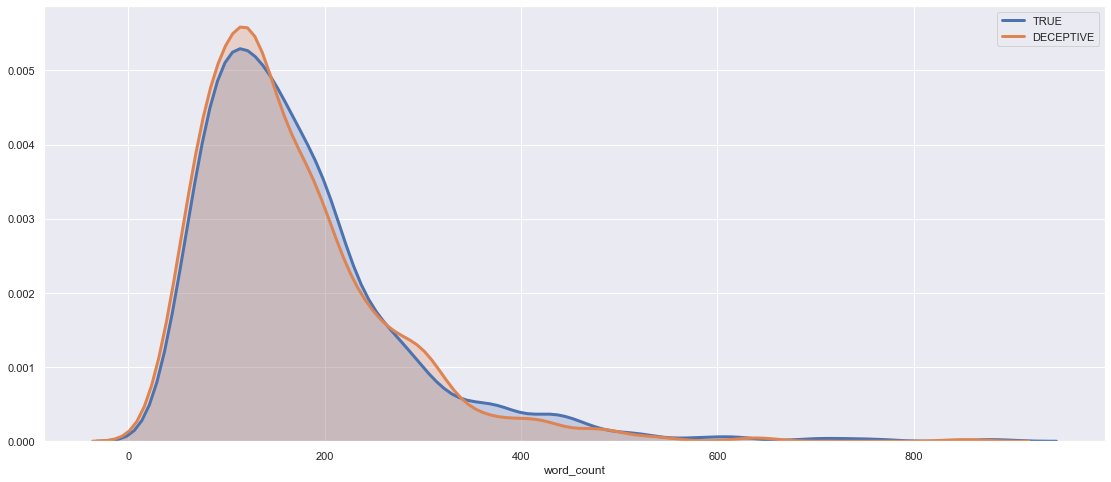

In [35]:
sns.set()
fig = plt.figure(figsize=(19, 8))
sns.distplot(df.loc[df.label== 'true', 'word_count'], hist = False, kde = True, 
             kde_kws = {'shade': True, 'linewidth': 3}, 
             label= 'TRUE')
sns.distplot(df.loc[df.label== 'deceptive', 'word_count'], hist = False, kde = True,
             kde_kws = {'shade': True, 'linewidth': 3}, 
             label= 'DECEPTIVE');

    From the graph:
    It is not necessary to have different word counts for true and deceptive reviews

In [36]:
count = lambda l1, l2: len(list(filter(lambda c: c in l2, l1)))
punc= list(set(string.punctuation))
def punc_count(row):
    return count(row, punc)

df['punc_count']= df.review.apply(punc_count)
    

    As we always say, it is pivotal to understand what's going on in the code we see. Hope you get the idea behind lambda. However, this is what the above lambda does:
    
    count occurances of any item of a list(In our case list of punctuation) in a string(In our case review).

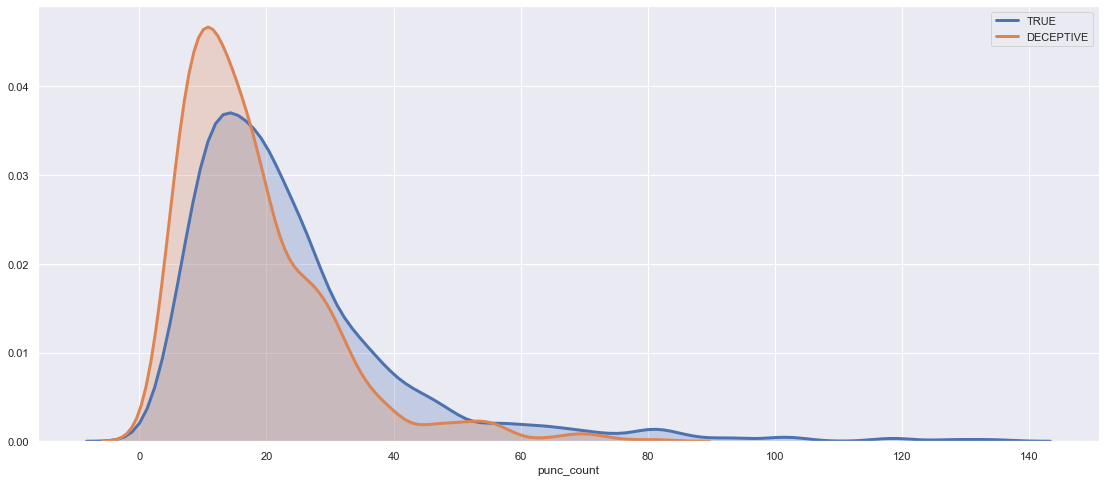

In [37]:
sns.set()
fig = plt.figure(figsize=(19, 8))
sns.distplot(df.loc[df.label== 'true', 'punc_count'], hist = False, kde = True, 
             kde_kws = {'shade': True, 'linewidth': 3}, 
             label= 'TRUE')
sns.distplot(df.loc[df.label== 'deceptive', 'punc_count'], hist = False, kde = True,
             kde_kws = {'shade': True, 'linewidth': 3}, 
             label= 'DECEPTIVE');

In [38]:
# Comapring Describe in the True and Deceptive Reviews
pd.DataFrame({'True': df[df.label == 'true']['punc_count'].describe().values, 
             'Deceptive': df[df.label == 'deceptive']['punc_count'].describe().values},
              index= df.describe().index)

,True,Deceptive
count,800.000000,800.000000
mean,23.870000,18.022500
std,17.290005,11.737833
min,1.000000,3.000000
25%,13.000000,10.000000
50%,20.000000,15.000000
75%,28.000000,24.000000
max,134.000000,81.000000


**Observations:**

    Punctuations in True Reviews are a bit more skewed towards the right comapred to the Deceptive.

In [39]:
pd.set_option('display.max_rows', 1600)
df['hotel_name_count']= df.apply(lambda x: str(x.review).lower().count(str(x.hotel)), axis = 1)

In [40]:
df.groupby(['label', 'polarity'])['hotel_name_count'].sum()

label      polarity
deceptive  negative    426
           positive    465
true       negative    271
           positive    302
Name: hotel_name_count, dtype: int64

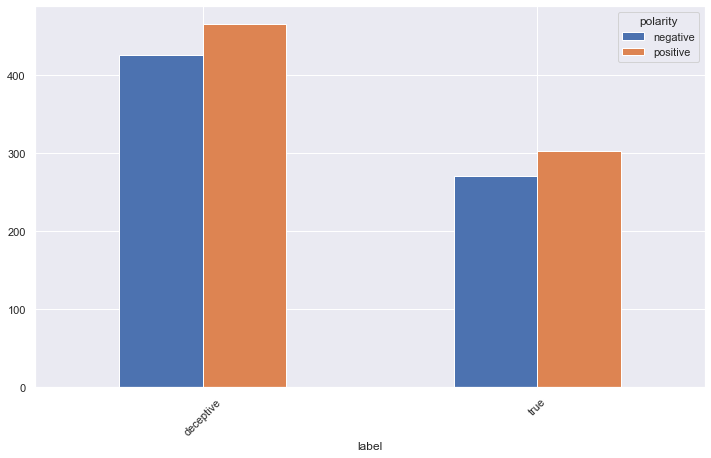

In [41]:
df.groupby(['label', 'polarity'])['hotel_name_count'].sum().unstack().plot(kind= 'bar', rot= 45, figsize= (12, 7));

**Observations:**

    Thats a great insight you can see right away that people writing deceptive reviews cites the names of Hotel a lot in their review.

In [42]:
df['unique_word_count']= df['spacy'].apply(lambda x: len(set(list(x))))

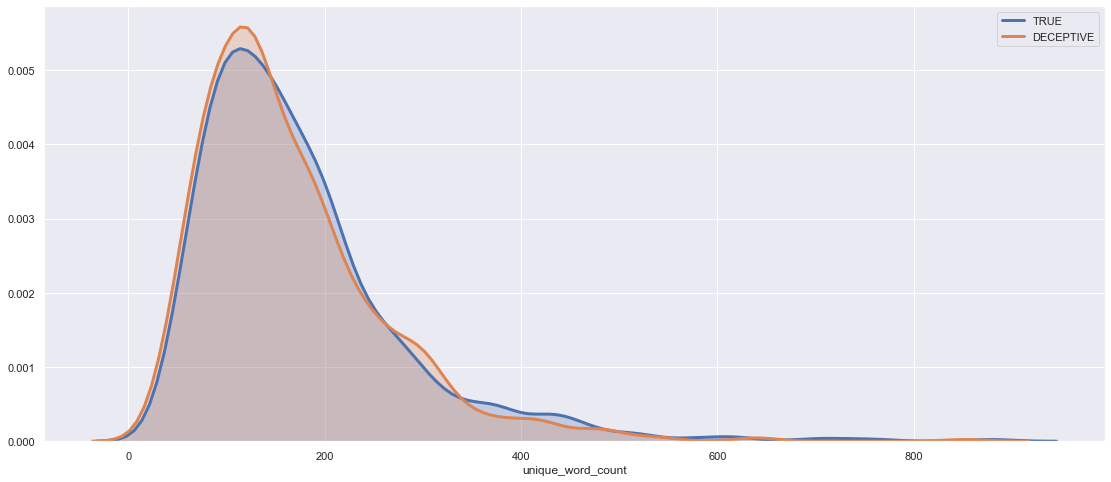

In [43]:
sns.set()
fig = plt.figure(figsize=(19, 8))
sns.distplot(df.loc[df.label== 'true', 'unique_word_count'], hist = False, kde = True, 
             kde_kws = {'shade': True, 'linewidth': 3}, 
             label= 'TRUE')
sns.distplot(df.loc[df.label== 'deceptive', 'unique_word_count'], hist = False, kde = True,
             kde_kws = {'shade': True, 'linewidth': 3}, 
             label= 'DECEPTIVE');

**Observations:**

    Same as Word Count there is no difference here as well.

In [44]:
print(nlp.Defaults.stop_words)

{'along', 'since', 'except', 'one', 'what', 'from', 'has', 'every', 'anyway', 'each', 'therefore', 'hereupon', 'will', 'name', '’ll', 'how', "'re", 'into', 'latter', 'three', 'move', 'always', 'him', 'everyone', 'his', 'against', '‘d', 'most', 'do', 'who', 'yours', "n't", 'have', 'upon', 'for', 'however', 'indeed', 'ourselves', 'whereafter', 'myself', 'top', 'afterwards', 'herself', 'been', 'during', 'whatever', 'did', 'whenever', 'can', 'again', 'n‘t', 'its', 'though', 'front', 'those', 'besides', 'anywhere', 'now', 'whoever', 'may', 'through', 'less', 'four', 'themselves', 'amount', 'does', 'thereafter', 'next', 'almost', 'hundred', 'than', '‘m', "'ll", '’m', 'own', 'mine', 'our', 'when', 'everywhere', 'about', 'it', "'m", 'someone', 'third', 'are', 'around', 'due', 'nothing', 'these', 'becomes', 'many', 'why', 'of', 'sixty', 're', 'would', 'thru', 'whence', 'further', 'too', 'us', 'back', 'could', 'without', 'whereas', 'we', 'or', 'thereupon', 'should', 'neither', 'eight', 'moreover

*We are going to use all the stop words available in spacy Language Model.*

In [45]:
count = lambda l1, l2: len(list(filter(lambda c: c in l2, l1)))
stop= list(nlp.Defaults.stop_words)

df['stop_count']= df.review.apply(lambda x: count(x, stop))

*We are going to use the same count Function, I used for counting the number of punctuation, but here instead of punctuations we have list of stop words.*

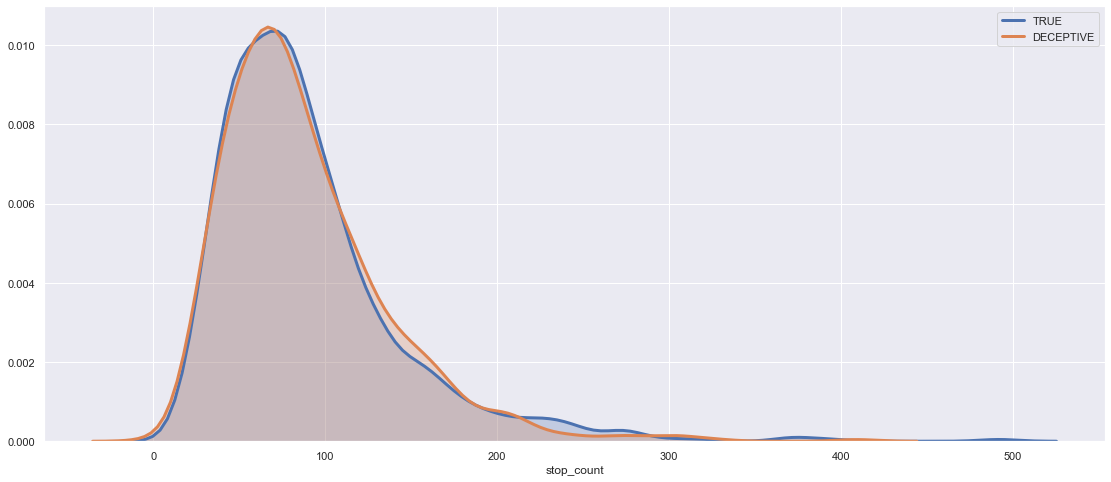

In [46]:
sns.set()
fig = plt.figure(figsize=(19, 8))
sns.distplot(df.loc[df.label== 'true', 'stop_count'], hist = False, kde = True, 
             kde_kws = {'shade': True, 'linewidth': 3}, 
             label= 'TRUE')
sns.distplot(df.loc[df.label== 'deceptive', 'stop_count'], hist = False, kde = True,
             kde_kws = {'shade': True, 'linewidth': 3}, 
             label= 'DECEPTIVE');

**Observations**

    Not Much Difference in Stop Words usage

*This Below function takes in the DataFrame and returns a dataframe comparing the POS tags counts in the true and deceptive reviews.*

In [47]:

def pos_tag_count(df):
    
    # Create to empty lists in which we will store the list of POS Tags
    
    dec_pos_tags= list()
    true_pos_tags= list()
    # Iterate over Each Spacy Document Object
    
    for doc in df[df.label == 'true'].spacy:
        TAG_count = doc.count_by(spacy.attrs.TAG)
        true_dict = dict()
        
        # Spacy Returns a dictionary object with Hash Value of Pos and Counts
        # After every Iteration Update the POS Tag distioanry
        
        for key,value in sorted(TAG_count.items()):
            true_dict.update({ doc.vocab[key].text : value})
            
        # After updating the dict append it to the list we created at the very beiginning
        
        true_pos_tags.append(true_dict)
    
    # Then just follow the same above steps for the deceptive reviews as well  
    for doc in df[df.label == 'deceptive'].spacy:
        TAG_count = doc.count_by(spacy.attrs.TAG)
        dec_dict = dict()
        for key,value in sorted(TAG_count.items()):
            dec_dict.update({ doc.vocab[key].text : value})
        dec_pos_tags.append(dec_dict)
    
    '''    
    NoW the above returns a count object for each review in True and Deceptive we need to add them up
    for whole DataFrame using a counter object
    '''
    true_tag_count = Counter()
    for i in range(0,len(true_pos_tags)):
        true_tag_count = true_tag_count + Counter(true_pos_tags[i])
    dec_tag_count = Counter()
    for i in range(0,len(dec_pos_tags)):
        dec_tag_count = dec_tag_count + Counter(dec_pos_tags[i])
    true_tag_count = dict(true_tag_count)
    dec_tag_count = dict(dec_tag_count)
    
    ## Now Create a DataFrame for True Reviews with POS Tags and Counts
    true_pos = pd.DataFrame()
    true_pos['tag'] = true_tag_count.keys()
    true_pos['true_cnt'] = true_tag_count.values()
    
    ## Now Create a DataFrame for Deceptive Reviews with POS Tags and Counts
    dec_pos = pd.DataFrame()
    dec_pos['tag'] = dec_tag_count.keys()
    dec_pos['dec_cnt'] = dec_tag_count.values()
    
    # Merge these two DataFrames on Tag name
    reviews_tags = true_pos.merge(dec_pos, on='tag', how='left')
    reviews_tags = reviews_tags.set_index('tag')
    return reviews_tags

In [48]:
pos_tag_count(df).head(10)

,true_cnt,dec_cnt
tag,,
SYM,210,28.0
RB,9044,9021.0
NNS,4656,3948.0
IN,13469,13099.0
VBG,1669,1897.0
-RRB-,541,153.0
",",4561,4173.0
VBN,2356,2287.0
PRP$,1904,2749.0


*The above function takes in the DataFrame and returns the count of the POS tags in true and deceptive reviews setting the index to the POS Tags.*

### POS Tags Counts in Positive Reviews

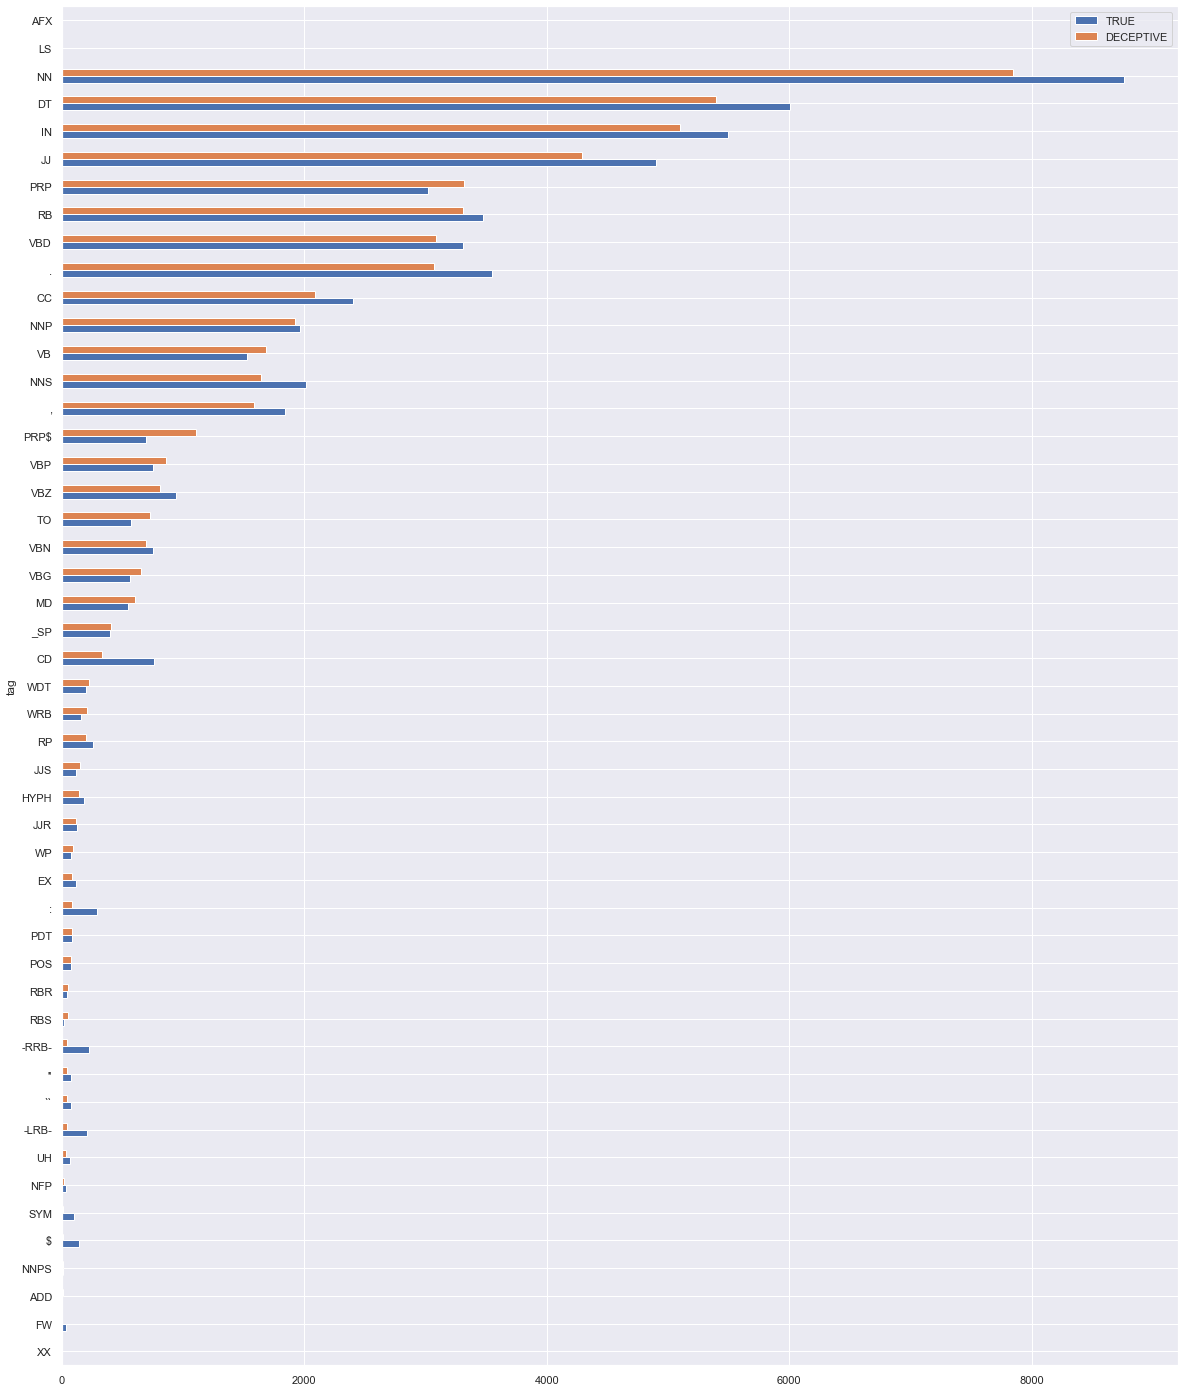

In [49]:
fig, ax = plt.subplots(figsize=(20, 25))
pos_tag_count(df[df.polarity == 'positive']).sort_values(by=['dec_cnt']).plot(kind= 'barh', rot=0, ax=ax);
ax.legend(['TRUE', 'DECEPTIVE']);

**Observations in Positive Reviews:**

**Personal Pronoun (PRP)**
> I, he, she, it

*The count of PRP(Personal pronoun) is higher is Deceptive compared to the true Reviews.*

**Possesive Pronoun (PRP$)**
> my, his, her

*The count of PRP$(Possesive Pronoun) is higher is Deceptive compared to the true Reviews.*

**Verb, non-3rd person singular present (VBP)**
> am, are

*The count of VBP(Verb, non-3rd person singular present) is higher is Deceptive compared to the true Reviews.*


***Note: We Will use these in the POS Tag filtering in one of our later sections.***

### POS Tags counts in Negative Reviews

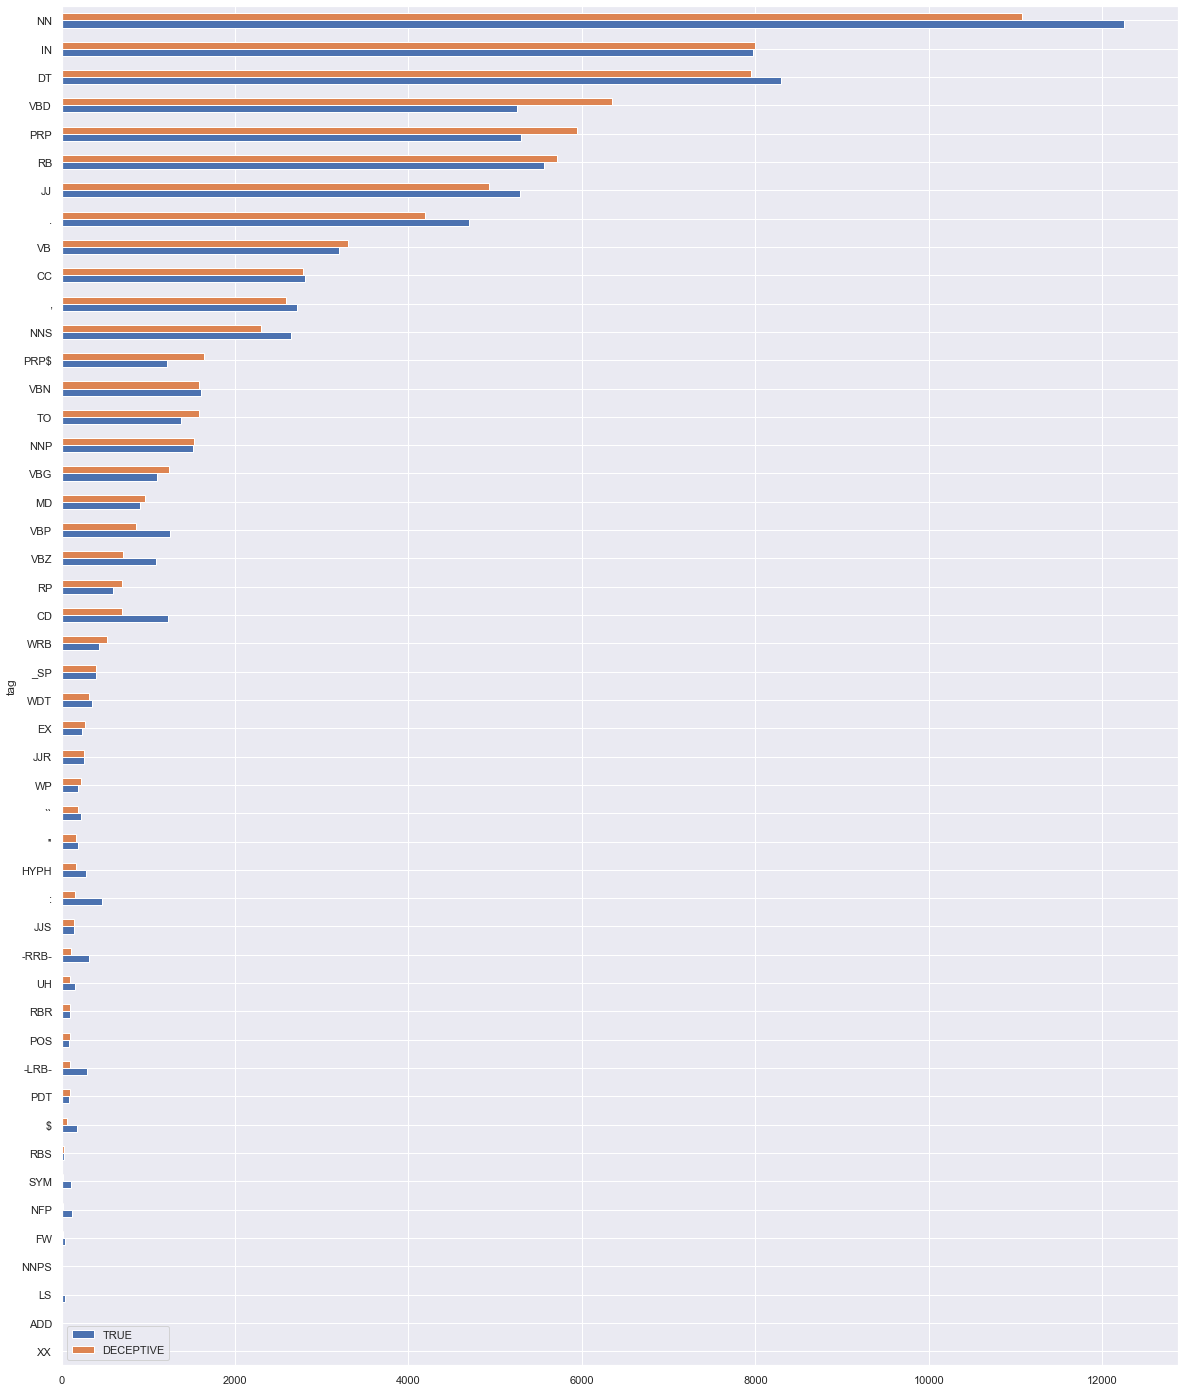

In [50]:
fig, ax = plt.subplots(figsize=(20, 25))
pos_tag_count(df[df.polarity == 'negative']).sort_values(by=['dec_cnt']).plot(kind= 'barh', rot=0, ax=ax);
ax.legend(['TRUE', 'DECEPTIVE']);

**Observations in Negative Reviews:**

**Personal Pronoun (PRP)**
> I, he, she, it

*The count of PRP(Personal pronoun) is higher is Deceptive compared to the true Reviews.*

**Possesive Pronoun (PRP$)**
> my, his

*The count of PRP$(Possesive Pronoun) is higher is Deceptive compared to the true Reviews.*

**Verb, past tense (VBD)**
> was, were

*The count of VBD(Verb, past tense) is higher is Deceptive compared to the true Reviews.*


***Note: We Will use these in the POS Tag filtering in one of our later sections.***

### POS Tags Combining Positive and Negative Sentiments

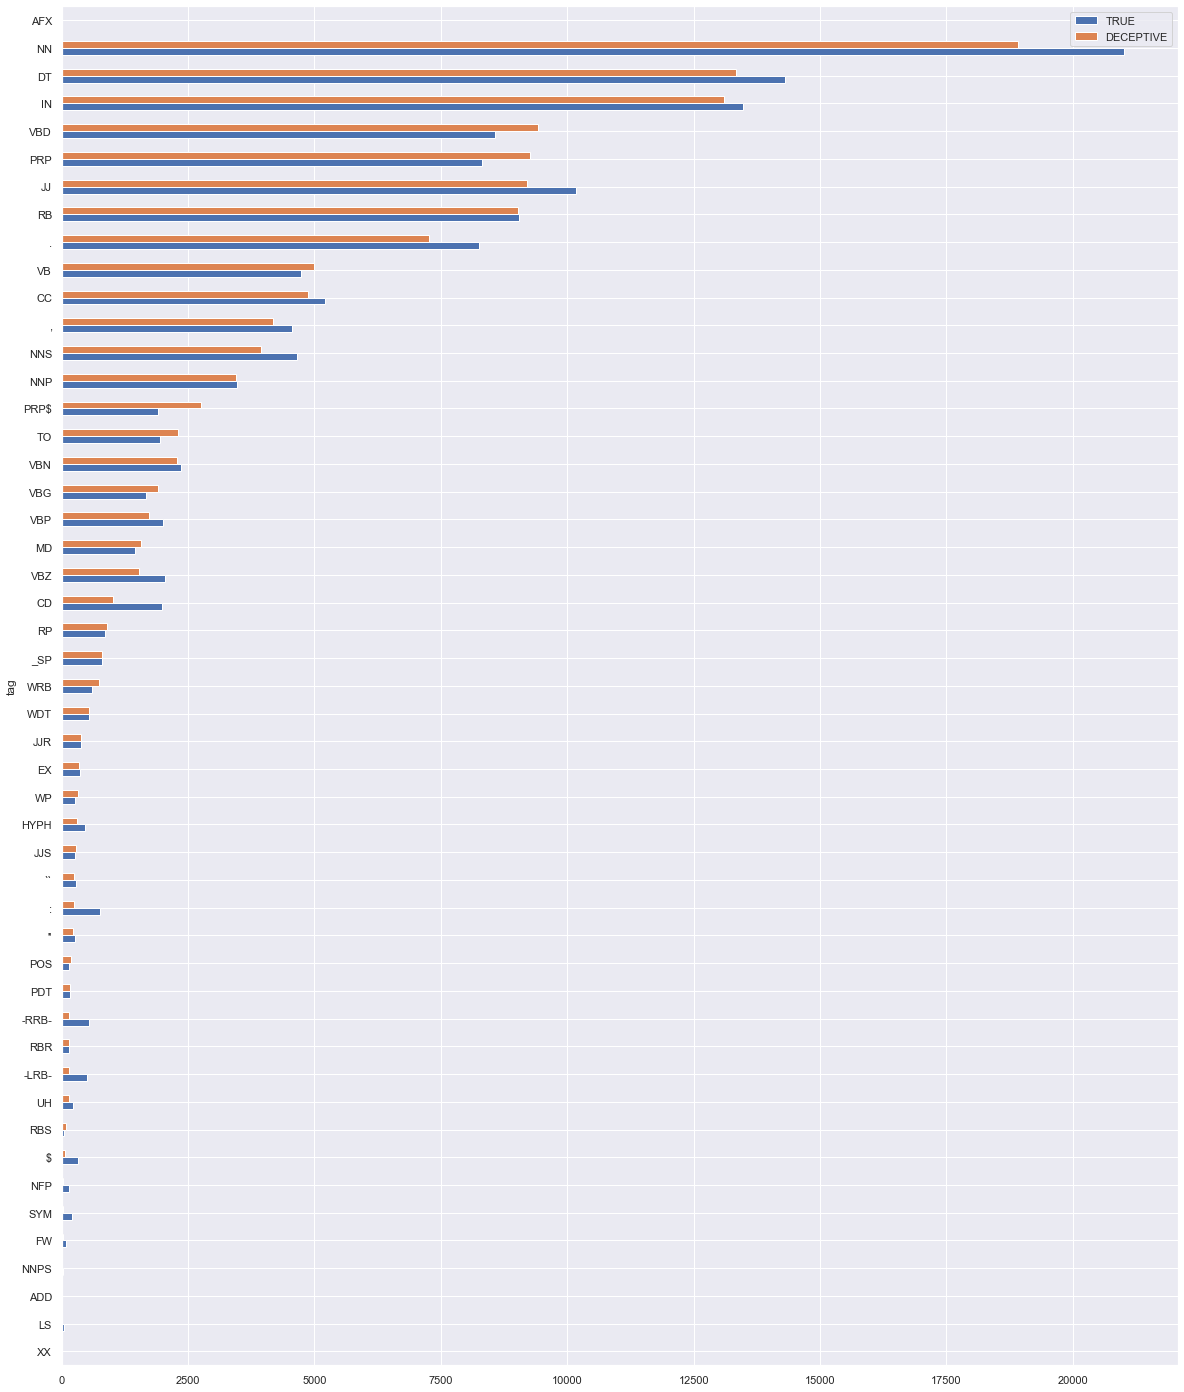

In [51]:
fig, ax = plt.subplots(figsize=(20, 25))
pos_tag_count(df).sort_values(by=['dec_cnt']).plot(kind= 'barh', rot=0, ax=ax);
ax.legend(['TRUE', 'DECEPTIVE']);

**Observations in Combined Positive and Negative Reviews:**

**Personal Pronoun (PRP)**
> I, he,she,  it

*The count of PRP(Personal pronoun) is higher is Deceptive compared to the true Reviews.*

**Possesive Pronoun (PRP$)**
> my, his, her

*The count of PRP$(Possesive Pronoun) is higher is Deceptive compared to the true Reviews.*


***Note: We Will use these in the POS Tag filtering in one of our later sections.***

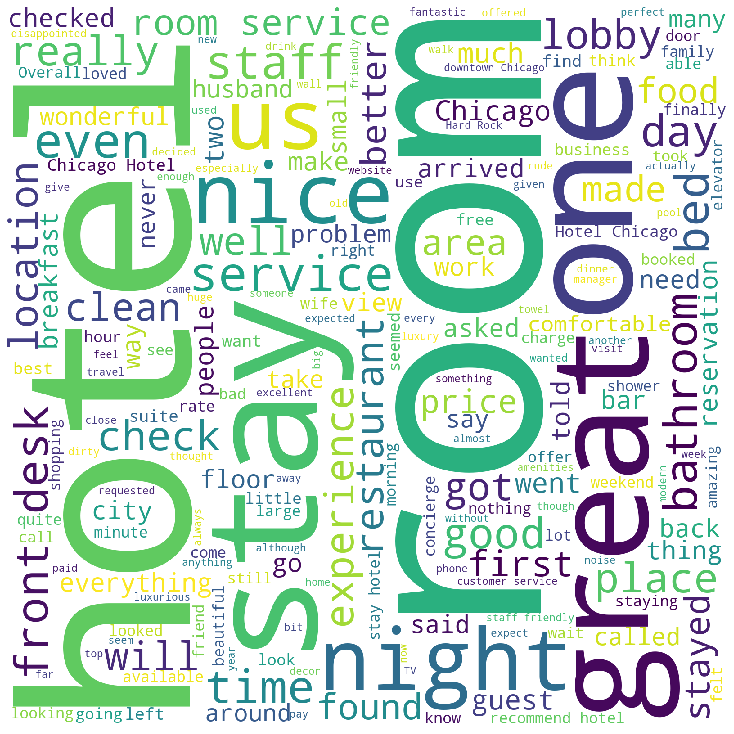

In [61]:
# Python program to generate WordCloud  
plt.figure(figsize=(10,14))
plt.axis("off") 
plt.tight_layout(pad = 0) 

wordcloud = WordCloud(width = 1600, height = 1600, 
                background_color ='white',  
                min_font_size = 10).generate(".".join(df.review)) 
  
# plot the WordCloud image
plt.imshow(wordcloud)


**Observations:**

*Most used words in the reviews are hotel, room, stay, great, service.*

### Most frequent words in True Reviews

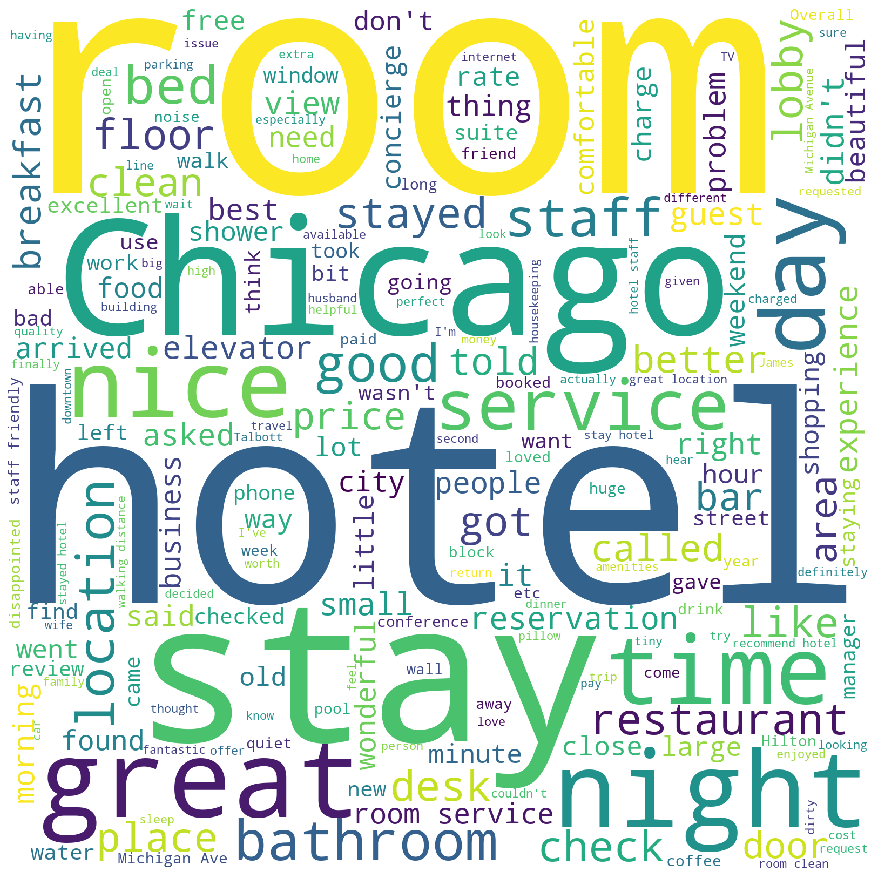

In [62]:
wordcloud = WordCloud(width = 1600, height = 1600, 
                background_color ='white',
                      stopwords= stop,
                min_font_size = 10).generate(".".join(df[df.label == 'true'].review)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (12, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
  
plt.show()

### Most frequent words in Deceptive Reviews

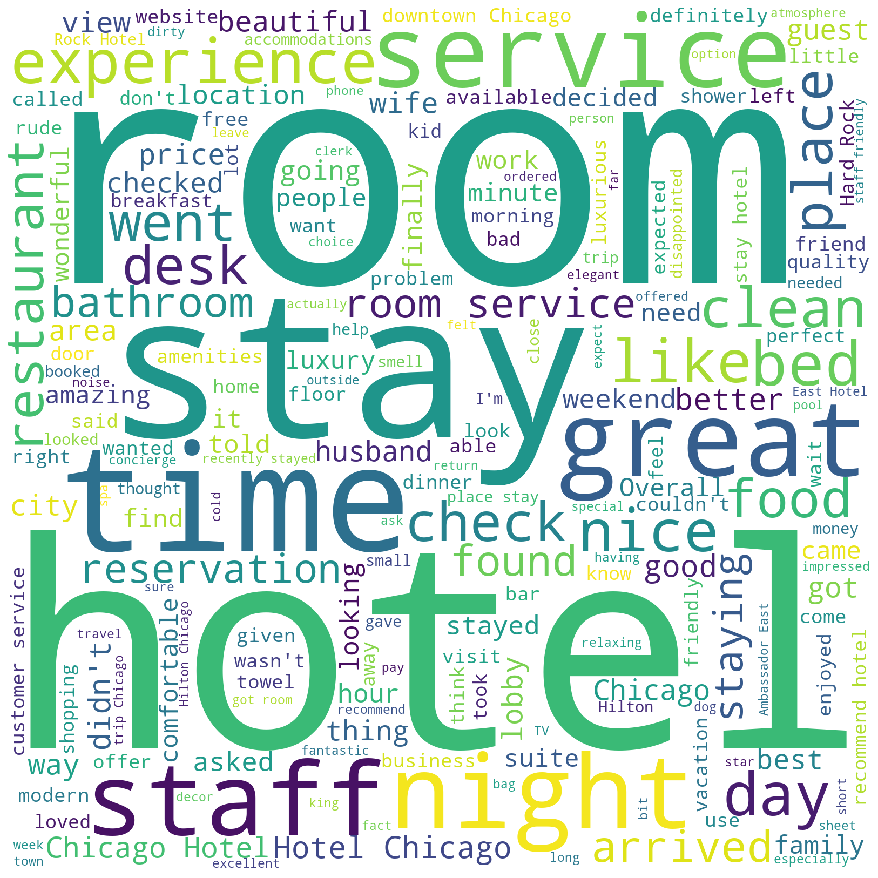

In [63]:
wordcloud = WordCloud(width = 1600, height = 1600, 
                background_color ='white',
                      stopwords= stop,
                min_font_size = 10).generate(".".join(df[df.label == 'deceptive'].review)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (12, 12), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
  
plt.show()

Storing the text in X, that is out Indepnedent Variable and Storing the labels in y that is our dependent variable.

In [64]:
X= df.review
y = df.label

## Text Preprocessing

In [65]:
def preprocess(text):
    
    # Lower the Text
    text= text.lower()
    
    # Passing the text into SpaCy Document Object
    doc= nlp(text)
    
    # Extracting tokens out of SpaCy Document Object
    tokens= [str(t) for t in doc]
    
    # Removing the Punctuation
    tokens= [word.translate(str.maketrans('', '', string.punctuation)) for word in tokens]
    
    # remove words that contain numbers
    tokens = [word for word in tokens if not any(c.isdigit() for c in word)]
    
    # remove empty tokens
    tokens = [t for t in tokens if len(t) > 0]
    
    return tokens

## TFIDF Vectoriser

*Using Sklearn TFIDFVectoriser*<br>
*Everytime you run TFIDF vectoriser, you need to pass in a tokenizer otherwise it takes in TFIDF's default tokenizer.*

*You can see I passed my preprocessing function to the tokenier!! Whats happens there is when you call fit function on your trainning data, each datapoint in your review first passes to `preprocess` and then applies tfidf on list of words.*

In [66]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
import nltk
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.model_selection import cross_val_score
from tqdm import tqdm
import gensim

tfidf_vectorizer = TfidfVectorizer(tokenizer= preprocess, ngram_range=(1,2), max_features = 5000, lowercase=False)
tfid = tfidf_vectorizer.fit_transform(X)

In [67]:
dense = tfid.todense()
dense.shape

(1600, 5000)

*Converting the dense into DataFrame.*

In [68]:
x= pd.DataFrame(dense)

### Test Train Split

In [69]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

### Model Building

In [70]:
# Fitting a simple logistic Regression Model
lr = LogisticRegression()
lr.fit(X_train,y_train)

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=100,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=None, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False)

In [71]:
y_pred= lr.predict(X_test)

In [74]:
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

   deceptive       0.87      0.86      0.87       196
        true       0.87      0.88      0.87       204

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87       400
weighted avg       0.87      0.87      0.87       400



In [75]:
print("Training Set Accuracy: ", accuracy_score(y_train, lr.predict(X_train)))
print("Test Set Accuracy: ", accuracy_score(y_test, y_pred))

Training Set Accuracy:  0.965
Test Set Accuracy:  0.87


*You can see that the model is overfitting. Our Trainning set accuracy is 96 % while our test set Accuracy is 89 %. And that too with a very basic linear classifier. Try tunning the Hyperpameters:*

- max_df
- ngram_range
- max_features

*Use the code below for tunning the Hyper Parameters.*

### Tunning TFIDF Vectoriser

In [77]:
## Create a pipeline which takes in tfidf vectoriser first and then a simple logistic Regression Model
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(tokenizer= preprocess, lowercase=False)),
    ('clf', LogisticRegression()),
])

In [78]:
## Pass in the Parameters in the pipeline 
## as these parameters belong to the tfidf in pipeline thats why you need to specify tfidf__ before the parameters
parameters = {
    'tfidf__max_df': [0.25, 0.5, 0.75],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__max_features': [1000, 1500, 2000, 2500, 3000]
}

grid_search_tune = GridSearchCV(pipeline, parameters, cv=5)
grid_search_tune.fit(X, y)

print("Best parameters set:")
print(grid_search_tune.best_estimator_.steps)

Best parameters set:
[('tfidf', TfidfVectorizer(analyzer='word', binary=False, decode_error='strict',
                dtype=<class 'numpy.float64'>, encoding='utf-8',
                input='content', lowercase=False, max_df=0.25,
                max_features=3000, min_df=1, ngram_range=(1, 2), norm='l2',
                preprocessor=None, smooth_idf=True, stop_words=None,
                strip_accents=None, sublinear_tf=False,
                token_pattern='(?u)\\b\\w\\w+\\b',
                tokenizer=<function preprocess at 0x0000015F3C48D438>,
                use_idf=True, vocabulary=None)), ('clf', LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=100,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=None, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False))]


*Shape of Training Data*

In [79]:
X_train.shape

(1200, 5000)

*We are training on 1200 data points with 5000 features, your model has been cursed by dimensionality. So even a linear classifier (Logistic Regression) is overfitting. The only way to reduce this overfitting is by getting more data which is not possible in our case otherwise do some feature selection to get best features our of these 5000 features.*

*In the `Exploratory Data Anlysis Section` we comapred the pos tags count in the True and Deceptive reviews. There I mentioned as a note we are going to use these in POS tag filtering. So, Instead passing all the text we are filtering th text for some POS tags which are going to help the classifier.*

## Filtering POS Tags

In [80]:
X[0]

'My husband and I satayed for two nights at the Hilton Chicago,and enjoyed every minute of it! The bedrooms are immaculate,and the linnens are very soft. We also appreciated the free wifi,as we could stay in touch with friends while staying in Chicago. The bathroom was quite spacious,and I loved the smell of the shampoo they provided-not like most hotel shampoos. Their service was amazing,and we absolutely loved the beautiful indoor pool. I would recommend staying here to anyone.\n'

In [82]:
# Allowed POS Tags
allowed_word_types = ["PRP", "JJ", "NNP", "NNS", "PRP$", "VBD", "VB"]

    Why did we have to limit the POS tags used?
---
    
    Not all vocabulary contributes to intent of any given text only words like adjective, verbs... add value to analysis and hence we will create vocabulary only with the above tags

In [83]:
nltk.pos_tag(['we'])

[('we', 'PRP')]

In [84]:
all_words = []
for p in tqdm(X):
    # Preprocessing the text
    words = preprocess(p)
    # Getting the POS tags using NLTK pos_tags function
    pos = nltk.pos_tag(words)
    #####################################################################################################
    ### POS will have list of tuples where a tuple is a combination of word and POS Tag ('we', 'PRP') ###
    #####################################################################################################
    for w in pos:
        ### w is a tuple and second element is POS Tag 
        if w[1] in allowed_word_types:
            ## W[0] is the word
            all_words.append(str(w[0]))        
pos_word_final = list(set(all_words))

100%|██████████████████████████████████████████████████████████████████████████████| 1600/1600 [00:46<00:00, 34.21it/s]


In [85]:
# Now TF-IDF vectorizer will form vocabulary on these words, that will form features essentially.
tfidf_vectorizer = TfidfVectorizer(tokenizer= preprocess, ngram_range=(1,1), vocabulary = pos_word_final)
tfid = tfidf_vectorizer.fit_transform(X)
dense = tfid.todense()
x = pd.DataFrame(dense)

In [86]:
x.shape

(1600, 4908)

In [87]:
X_new = SelectPercentile(chi2, percentile=10).fit_transform(x, y)

In [88]:
X_new.shape

(1600, 491)

In [89]:

X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size=0.25, random_state=42)

### Model Building

In [90]:
lr = LogisticRegression()
lr.fit(X_train,y_train)

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=100,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=None, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False)

In [91]:
y_pred= lr.predict(X_test)

In [92]:
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

   deceptive       0.83      0.86      0.85       187
        true       0.87      0.85      0.86       213

    accuracy                           0.85       400
   macro avg       0.85      0.85      0.85       400
weighted avg       0.85      0.85      0.85       400



In [93]:
print("Training Set Accuracy: ", accuracy_score(y_train, lr.predict(X_train)))
print("Test Set Accuracy: ", accuracy_score(y_test, y_pred))

Training Set Accuracy:  0.8966666666666666
Test Set Accuracy:  0.8525


*Lets try cross val score to check whether the model is overfitting or not.*

In [95]:
scores = cross_val_score(lr, X_train,y_train, cv=5)

In [96]:
scores

array([0.78333333, 0.85416667, 0.87083333, 0.85      , 0.91666667])

*There is serious overfit, this model might work well on the data it has seen but will fail on the unseen data.*

*Still the same problem persists we are overfitting, lets try word embeddings precisely Google's Word2Vec.*

## Using Pre-Trained Word Embeddings

    Terminology alert! what is pre-trained? what is word embeding?
---
    
    Pre trained is simply a model trained earlier, this will help because a model has been built after extensive training on huge corpuses of data, research and experimentation. 
    Word Embeddings is a concept that converts words into vectors with features representing characteristics of the word in question. There are many algorithms that provide word embeddings, one such models is Google's word2vec

### Google's Word2Vec

*First Lets download Pretrained Word Vectors*

In [97]:
wget.download('https://s3.amazonaws.com/dl4j-distribution/GoogleNews-vectors-negative300.bin.gz')

100% [....................................................................] 1647046227 / 1647046227

'GoogleNews-vectors-negative300.bin.gz'

*Load these vectors using gensim*

In [98]:
google_word2vec= gensim.models.KeyedVectors.load_word2vec_format('GoogleNews-vectors-negative300.bin.gz', binary=True)

In [99]:
google_word2vec['hello'].shape

(300,)

    The above is output of the word2vec model, what can you make of it?
---

    As discussed earlier, a word is converted to vector of 300 dimensions. So, we are going to average out the word vectors for each row of data.

*The function below takes in a sentence and averages out the word vectors for the whole sentence, so you get the 300 dimensional sentence as a result.*

In [100]:
def get_mean_vector(words):
    # remove out-of-vocabulary words
    words = [word for word in words if word in google_word2vec.vocab]
    if len(words) >= 1:
        return np.mean(google_word2vec[words], axis=0)
    else:
        return []

In [101]:
x= df.spacy.apply(lambda x: get_mean_vector([str(word) for word in x]))

In [102]:
x.shape

(1600,)

*After appling mean vector, we get back 1600 dimension array, but it should be (1600, 300).*

*Convert this to DataFrame*

In [103]:
x = pd.DataFrame(x)

In [104]:
x.head()

,spacy
0,"[0.013063151, 0.01949847, 0.02959371, 0.105753..."
1,"[0.0013524775, 0.032445908, 0.01422012, 0.1264..."
2,"[0.020513142, 0.046133026, 0.02371894, 0.10634..."
3,"[-0.019301876, 0.022479212, 0.028402431, 0.133..."
4,"[0.024656048, 0.04691115, 0.018891638, 0.10469..."


*Apply pd.series, so it will covert element of list to a column.*

In [105]:
x= x.spacy.apply(pd.Series)

In [106]:
x.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,...,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299
0,0.013063,0.019498,0.029594,0.105753,-0.043790,0.021720,-0.000372,-0.092838,0.051591,0.073924,-0.035990,-0.159463,-0.025055,-0.005100,-0.043530,0.038758,0.071893,0.089215,0.016277,-0.016364,-0.044384,0.050789,0.036779,-0.024887,0.011413,0.020835,-0.081819,0.058536,-0.004091,-0.040436,-0.027694,0.001269,-0.036299,0.010142,0.018490,-0.027779,-0.009332,-0.031865,0.023681,0.032272,0.061845,-0.063373,0.115435,0.025937,0.015687,-0.011883,-0.000767,-0.004338,-0.000848,0.007841,...,0.015417,0.072174,0.109230,0.076641,0.065587,-0.056761,0.005616,0.003569,-0.061391,-0.035183,0.016121,-0.013939,-0.037747,0.061705,0.051547,0.128762,-0.017911,-0.030133,-0.028364,0.006771,0.027484,0.070389,0.066261,0.076220,0.099927,-0.048912,-0.036775,-0.097981,-0.046536,-0.048861,0.048620,0.008661,0.010660,0.077138,0.011451,0.025654,-0.072810,-0.044446,-0.022687,0.067493,-0.068996,0.057274,-0.076283,0.007834,-0.020160,-0.029502,-0.018757,-0.042404,0.044996,-0.016754
1,0.001352,0.032446,0.014220,0.126484,-0.069070,-0.004924,0.015834,-0.068319,0.035025,0.061595,-0.045962,-0.146962,-0.042198,-0.000958,-0.051553,0.063349,0.054204,0.084181,0.001557,-0.038062,-0.044034,0.021994,0.036072,-0.039142,0.010738,0.015584,-0.086836,0.059469,0.002941,-0.026760,-0.044142,0.035625,-0.024498,-0.019222,0.013194,-0.036463,-0.025038,-0.029963,0.031970,0.048004,0.057205,-0.034437,0.117648,0.019491,-0.011108,-0.045038,-0.015817,0.002610,0.002967,0.016988,...,0.024281,0.039729,0.079082,0.038069,0.050665,-0.069223,0.038559,0.036115,-0.056863,-0.055450,0.004247,-0.038997,-0.032355,0.052194,0.072514,0.116032,-0.011318,-0.013535,-0.047131,0.012860,0.046753,0.083730,0.097837,0.070925,0.049422,-0.064073,-0.035278,-0.117800,-0.031922,-0.031628,0.004254,-0.004543,0.039687,0.084076,-0.002527,0.016386,-0.067637,-0.023552,-0.004324,0.062654,-0.083171,0.077942,-0.084074,0.060028,0.002798,0.009148,-0.006892,-0.076056,0.050242,-0.051537
2,0.020513,0.046133,0.023719,0.106343,-0.048142,-0.019903,-0.001536,-0.099854,0.050569,0.060714,-0.059235,-0.118060,-0.010435,-0.009675,-0.039761,0.009427,0.041402,0.061299,0.027275,-0.033647,-0.022435,0.031664,-0.021219,-0.012441,0.011329,0.028922,-0.058758,0.086561,0.019206,-0.003984,0.003278,0.004602,-0.038269,0.021930,0.002782,0.005111,-0.038845,-0.020331,0.048401,0.043933,0.029571,-0.058611,0.084899,0.027384,-0.019413,-0.014633,0.026840,-0.028246,-0.014579,0.035880,...,0.034895,0.056683,0.074870,0.036922,0.036014,-0.057950,0.021407,0.015554,-0.064013,-0.051113,0.005693,-0.030757,-0.009569,0.078130,0.072148,0.135851,0.006350,-0.015758,-0.022810,-0.010881,0.051266,0.059243,0.049517,0.029372,0.077989,-0.045395,-0.027164,-0.111246,-0.064717,-0.043821,0.027573,-0.008019,-0.005373,0.075646,0.004300,0.044317,-0.104635,-0.031731,-0.029236,0.009080,-0.080132,0.035104,-0.070305,0.037557,0.005203,-0.015418,-0.021400,-0.056870,0.049465,-0.021896
3,-0.019302,0.022479,0.028402,0.133442,-0.061235,-0.005426,0.033815,-0.077313,0.038750,0.076451,-0.049476,-0.163585,-0.006283,0.003340,-0.046486,0.053068,0.072281,0.054171,0.003815,-0.035635,-0.000032,0.027026,0.041357,-0.008275,0.044804,0.006812,-0.106955,0.077146,0.018365,-0.023609,-0.008089,-0.015786,-0.028324,0.008194,0.013774,0.004303,0.038569,-0.046429,0.009604,0.031685,0.052408,-0.066390,0.120809,-0.032817,0.032069,-0.054262,-0.051010,0.020524,0.034752,0.070289,...,0.021327,0.048620,0.100494,0.019148,0.052120,-0.083868,0.020186,0.023734,-0.076371,-0.064273,0.027422,0.015015,-0.055575,0.029810,0.033771,0.110738,-0.050187,-0.003492,-0.048387,-0.000022,0.046083,0.052320,0.067153,0.055498,0.114267,-0.054476,-0.031836,-0.086687,-0.047407,-0.021573,0.055048,0.008863,0.016769,0.063218,0

In [107]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

In [108]:
lr = LogisticRegression()
lr.fit(X_train,y_train)

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=100,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=None, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False)

In [109]:
y_pred= lr.predict(X_test)

In [110]:
print("Training Set Accuracy: ", accuracy_score(y_train, lr.predict(X_train)))
print("Test Set Accuracy: ", accuracy_score(y_test, y_pred))

Training Set Accuracy:  0.785
Test Set Accuracy:  0.785


In [111]:
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

   deceptive       0.78      0.78      0.78       196
        true       0.79      0.79      0.79       204

    accuracy                           0.79       400
   macro avg       0.78      0.78      0.78       400
weighted avg       0.78      0.79      0.78       400



*We have found our best vectorisation technique.*

*We are going to go ahead with this word2vec pretrined Model and try to fit some other complex models model.*

# Building Classification Models

In [112]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.10, random_state=42)

## Naive Bayes

In [113]:
from sklearn.naive_bayes import GaussianNB
NB = GaussianNB()
NB.fit(X_train, y_train)

GaussianNB(priors=None, var_smoothing=1e-09)

In [114]:
y_pred= NB.predict(X_test)

In [115]:
print("Training Set Accuracy: ", accuracy_score(y_train, lr.predict(X_train)))
print("Test Set Accuracy: ", accuracy_score(y_test, y_pred))

Training Set Accuracy:  0.7847222222222222
Test Set Accuracy:  0.7375


## K Nearest Neighbors

In [116]:
from sklearn.neighbors import KNeighborsClassifier
neigh = KNeighborsClassifier(n_neighbors=3)
neigh.fit(X_train, y_train)

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                     metric_params=None, n_jobs=None, n_neighbors=3, p=2,
                     weights='uniform')

In [117]:
y_pred= neigh.predict(X_test)

In [118]:
print("Training Set Accuracy: ", accuracy_score(y_train, lr.predict(X_train)))
print("Test Set Accuracy: ", accuracy_score(y_test, y_pred))

Training Set Accuracy:  0.7847222222222222
Test Set Accuracy:  0.75


## XGBoost Classifier

In [119]:
from xgboost import XGBClassifier
xgb = XGBClassifier(learning_rate=0.02, n_estimators=600, objective='binary:logistic',
                    silent=True, nthread=1)
xgb.fit(X_train, y_train)

XGBClassifier(base_score=0.5, booster=None, colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1, gamma=0, gpu_id=-1,
              importance_type='gain', interaction_constraints=None,
              learning_rate=0.02, max_delta_step=0, max_depth=6,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              n_estimators=600, n_jobs=1, nthread=1, num_parallel_tree=1,
              objective='binary:logistic', random_state=0, reg_alpha=0,
              reg_lambda=1, scale_pos_weight=1, silent=True, subsample=1,
              tree_method=None, validate_parameters=False, verbosity=None)

In [120]:
y_pred= xgb.predict(X_test)

In [121]:
print("Training Set Accuracy: ", accuracy_score(y_train, lr.predict(X_train)))
print("Test Set Accuracy: ", accuracy_score(y_test, y_pred))

Training Set Accuracy:  0.7847222222222222
Test Set Accuracy:  0.8125


    We got a very good accuracy with XGBoost Classifier, Lets try and improve the performance more... how?
---
    
    You got it! Hyperparameter tuning with Gridsearchcv or Randomsearchcv or even tuning parameters by hand. You can pick any of these depending on your expertise and preference. We prefer to use Gridsearchcv

## Tunning XGBoost Classifier

In [122]:
from sklearn.model_selection import GridSearchCV
params = {
        'min_child_weight': [1, 5, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'max_depth': [3, 4, 5]
        }
xgb = XGBClassifier(learning_rate=0.02, n_estimators=600, objective='binary:logistic',
                    silent=True, nthread=1)
grid_search_tune = GridSearchCV(xgb, params, cv=5, n_jobs= -1)
grid_search_tune.fit(X_train, y_train)

GridSearchCV(cv=5, error_score=nan,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, gamma=None,
                                     gpu_id=None, importance_type='gain',
                                     interaction_constraints=None,
                                     learning_rate=0.02, max_delta_step=None,
                                     max_depth=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     n_estim...
                                     reg_lambda=None, scale_pos_weight=None,
                                     silent=True, subsample=None,
                                     tree_method=None,
                                     validate_parameters=False,
                     

In [123]:
print("Best parameters set:")
print(grid_search_tune.best_estimator_)

Best parameters set:
XGBClassifier(base_score=0.5, booster=None, colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1.0, gamma=1.5, gpu_id=-1,
              importance_type='gain', interaction_constraints=None,
              learning_rate=0.02, max_delta_step=0, max_depth=3,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              n_estimators=600, n_jobs=1, nthread=1, num_parallel_tree=1,
              objective='binary:logistic', random_state=0, reg_alpha=0,
              reg_lambda=1, scale_pos_weight=1, silent=True, subsample=0.6,
              tree_method=None, validate_parameters=False, verbosity=None)


In [124]:
xgb = XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1.0, gamma=0.5,
              learning_rate=0.02, max_delta_step=0, max_depth=5,
              min_child_weight=5, missing=None, n_estimators=600, n_jobs=1,
              nthread=1, objective='binary:logistic', random_state=0,
              reg_alpha=0, reg_lambda=1, scale_pos_weight=1, seed=None,
              silent=True, subsample=0.6, verbosity=1)
xgb.fit(X_train, y_train)

XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1.0, gamma=0.5, gpu_id=-1,
              importance_type='gain', interaction_constraints=None,
              learning_rate=0.02, max_delta_step=0, max_depth=5,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              n_estimators=600, n_jobs=1, nthread=1, num_parallel_tree=1,
              objective='binary:logistic', random_state=0, reg_alpha=0,
              reg_lambda=1, scale_pos_weight=1, seed=0, silent=True,
              subsample=0.6, tree_method=None, validate_parameters=False,
              verbosity=1)

In [125]:
y_pred= xgb.predict(X_test)

In [126]:
print("Training Set Accuracy: ", accuracy_score(y_train, lr.predict(X_train)))
print("Test Set Accuracy: ", accuracy_score(y_test, y_pred))

Training Set Accuracy:  0.7847222222222222
Test Set Accuracy:  0.825


# Model Selection

*We are going to use this XGBoost model as final model.*

In [128]:
y_pred= xgb.predict(X_test)

In [129]:
print("Training Set Accuracy: ", accuracy_score(y_train, lr.predict(X_train)))
print("Test Set Accuracy: ", accuracy_score(y_test, y_pred))

Training Set Accuracy:  0.7847222222222222
Test Set Accuracy:  0.825


In [130]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

   deceptive       0.86      0.80      0.82        83
        true       0.80      0.86      0.82        77

    accuracy                           0.82       160
   macro avg       0.83      0.83      0.82       160
weighted avg       0.83      0.82      0.82       160



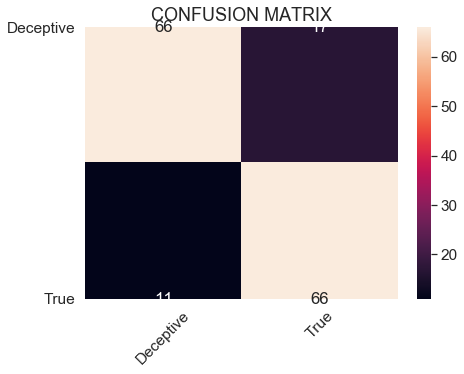

In [132]:
cm = confusion_matrix(y_test, y_pred)
df_cm = pd.DataFrame(cm, index = (0, 1), columns = (0, 1))
plt.figure(figsize = (7,5))
sns.set(font_scale=1.4)
sns.heatmap(df_cm, annot=True, fmt='g', xticklabels=['Deceptive', 'True'], yticklabels=['Deceptive', 'True'])
plt.xticks(rotation=45)
plt.yticks(rotation='horizontal')
plt.title("CONFUSION MATRIX", fontsize= 18)
plt.show();

# Formatting End Results

In [133]:
class deceptive:
    def __init__(self, text):
        self.test= nlp(text)
        
    def get_mean_vector(self, words):
        # remove out-of-vocabulary words
        words = [word for word in words if word in google_word2vec.vocab]
        if len(words) >= 1:
            return np.mean(google_word2vec[words], axis=0)
        else:
            return []
        
    def predict(self):
        self.test= [str(t) for t in self.test]
        self.vectors= self.get_mean_vector(self.test)
        return xgb.predict(pd.DataFrame([self.vectors]))[0]

In [134]:
X[0]

'My husband and I satayed for two nights at the Hilton Chicago,and enjoyed every minute of it! The bedrooms are immaculate,and the linnens are very soft. We also appreciated the free wifi,as we could stay in touch with friends while staying in Chicago. The bathroom was quite spacious,and I loved the smell of the shampoo they provided-not like most hotel shampoos. Their service was amazing,and we absolutely loved the beautiful indoor pool. I would recommend staying here to anyone.\n'

In [135]:
deceptive(X[0]).predict()

'deceptive'

*Try it out on your own Text.*

In [ ]:
deceptive("Put your text in here").predict()

### Next Steps:
    We are getting 82% accuracy, there's still room for improvement. Now we encourage you to go ahead and try feature engineering, hyperparameter tuning, trying out different models to improve scores. We would love to hear about your experience solving this datatale.
    
*Thats all from our side, Try exploring more on this Dataset and if you find anything else from this Dataset, do write in the feedback form and If you have any doubts feel free post it on the discussions forums.*